# Bregman proximal point minimization

Let $f$ and $h$ be closed, proper, convex functions on a finite-dimensional real Euclidean space, with the differentiability and well-definedness assumed in the input. Let $x_{\star}$ minimize $f$, $\alpha>0$, $R\ge0$, and $N\ge1$.

$$D_{h}(u,v)=h(u)-h(v)-\langle\nabla h(v),u-v\rangle,$$
$$D_{h}(x_{\star},x_{0})\le R,\qquad x_{k+1}\in\arg\min_{x}\{\alpha f(x)+D_{h}(x,x_{k})\},\quad 0\le k<N.$$
The update satisfies $\nabla h(x_{k+1})=\nabla h(x_{k})-\alpha\nabla f(x_{k+1})$. We study $f(x_{N})-f(x_{\star})$.

Convex interpolation supplies the finite PEP relaxation; no smoothness or strong convexity is imposed.

## Proof Statement

### Theorem

Under the stated Bregman proximal point assumptions, let $\alpha>0$, $R\ge0$, $N\ge1$ be an integer, and $D_{h}(x_{\star},x_{0})\le R$. No strong convexity of $h$ or Lipschitz gradient assumption is needed. Define
$$V_{0}=0,\qquad V_{k}=\frac{\alpha k\bigl(f(x_{k})-f(x_{\star})\bigr)+D_{h}(x_{\star},x_{k})-D_{h}(x_{\star},x_{0})}{\alpha N},\quad 1\le k\le N.$$
Then $V_{k+1}\le V_{k}$ and
$$0\le f(x_{N})-f(x_{\star})\le\frac{R}{\alpha N}.$$
The normalization is the supplied Bregman radius $R$, not $R^2$. The separate definition of $V_{0}$ does not require evaluating $f(x_{0})$.

### Proof outline

Write $I_{q}(u,v)=q(v)-q(u)+\langle\nabla q(v),u-v\rangle\le0$ for convex $q\in\{f,h\}$. Proximal optimality gives $\nabla h(x_{k+1})=\nabla h(x_{k})-\alpha\nabla f(x_{k+1})$.

Use $V_{0}=0$ and $V_{k}=k(f(x_{k})-f(x_{\star}))/N+[D_{h}(x_{\star},x_{k})-D_{h}(x_{\star},x_{0})]/(\alpha N)$ for $k\ge1$. The initial step is
$$V_{1}-V_{0}=\frac{1}{N}I_{f}(x_{\star},x_{1})+\frac{1}{\alpha N}I_{h}(x_{1},x_{0})\le0.$$
For $1\le k<N$, direct expansion and the proximal relation give the complete identity
$$V_{k+1}-V_{k}=\frac{1}{N}I_{f}(x_{\star},x_{k+1})+\frac{k}{N}I_{f}(x_{k},x_{k+1})+\frac{k+1}{\alpha N}I_{h}(x_{k+1},x_{k})+\frac{k}{\alpha N}I_{h}(x_{k},x_{k+1})\le0.$$
All multipliers are nonnegative, so $V_{N}\le V_{0}=0$. There are no additional squares or residual families in this exact local certificate. Finally,
$$f(x_{N})-f(x_{\star})-\frac{R}{\alpha N}=V_{N}+\frac{D_{h}(x_{\star},x_{0})-R}{\alpha N}+\frac{I_{h}(x_{\star},x_{N})}{\alpha N}\le0.$$
Here the last two terms are nonpositive by the initial condition and convexity, respectively. The lower bound follows because $x_{\star}$ minimizes $f$. When $N=1$, the initial step and boundary identity suffice; the proof also covers $R=0$.

In [1]:
import sys
from pathlib import Path

notebook_dir = Path.cwd().resolve()
repo_root = notebook_dir / "supplementary" / "approved"
sys.path[:0] = [
    str(repo_root),
    str(notebook_dir),
    str(notebook_dir / "supplementary" / "helpers"),
]

In [2]:
from typing import Any
import runtime  # ty: ignore[unresolved-import]  # Notebook bootstrap adds the helper directory to sys.path.
import json
import pepflow as pf
import matplotlib.pyplot as plt

print("Framework:", pf.__file__)

assert runtime.ROOT == notebook_dir

Framework: C:\Users\Jack\Documents\GitHub\PEPFlow\examples_peppy\_evaluations\20260923T140754Z_paper5_pgm_sos_6x5_isolation1\bppm\r01\supplementary\approved\pepflow\__init__.py


## Function and parameter definitions

In [3]:
alpha: Any = pf.Parameter("alpha")
R = pf.Parameter("R")
f = pf.ConvexFunction(is_basis=True, tags=["f"])
h = pf.ConvexFunction(is_basis=True, tags=["h"])

## Algorithm and PEP setup

In [4]:
def make_ctx_bppm(ctx_name, N, **kwargs):
    ctx = pf.PEPContext(ctx_name).set_as_current()
    x = pf.Vector(is_basis=True, tags=["x_0"])
    f.set_stationary_point("x_star")
    for k in range(N):
        x = f.bregman_prox(x, alpha, h, tag=f"x_{k + 1}")
    return ctx


def get_pep_setup(N, params):
    ctx = make_ctx_bppm(f"ctx_{N}", N)
    pb = pf.PEPBuilder(ctx)
    x0, xs = ctx["x_0"], ctx["x_star"]
    distance = h(xs) - h(x0) - h.grad(x0) * (xs - x0)
    pb.add_initial_constraint(distance.le(R, name="initial_condition"))
    pb.set_performance_metric(f(ctx[f"x_{N}"]) - f(xs))
    return ctx, pb, f

## Numerical evidence

N=1: PEP=0.9999999998, candidate=1.0000000000, status=optimal
N=2: PEP=0.4999999982, candidate=0.5000000000, status=optimal
N=3: PEP=0.3333333297, candidate=0.3333333333, status=optimal
N=4: PEP=0.2499999997, candidate=0.2500000000, status=optimal
N=5: PEP=0.1999999969, candidate=0.2000000000, status=optimal
N=6: PEP=0.1666666662, candidate=0.1666666667, status=optimal
N=7: PEP=0.1428571412, candidate=0.1428571429, status=optimal
Maximum discrepancy: 3.6219285903804632e-09
Inverse-rate increments: [1.0000000070746513, 1.0000000253205803, 0.9999999726304187, 1.000000071038766, 0.9999999394421275, 1.0000000668553914]


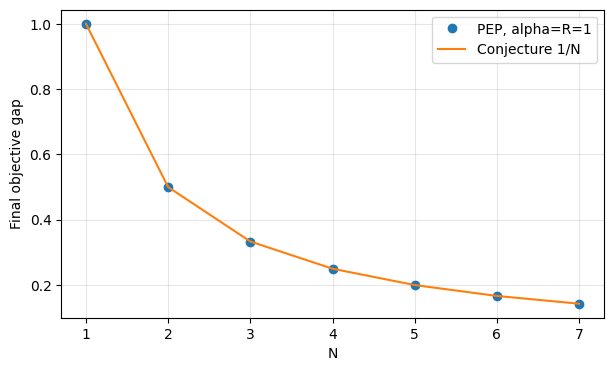

In [5]:
sweep = json.loads((notebook_dir / "supplementary" / "b1-sweep.json").read_text())
for row in sweep:
    print(
        f"N={row['N']}: PEP={row['opt_value']:.10f}, candidate={row['candidate']:.10f}, status={row['status']}"
    )
errors = [abs(row["error"]) for row in sweep]
assert max(errors) < 1e-5
print("Maximum discrepancy:", max(errors))
print(
    "Inverse-rate increments:",
    [1 / sweep[j + 1]["opt_value"] - 1 / sweep[j]["opt_value"] for j in range(6)],
)
plt.figure(figsize=(7, 4))
plt.plot(
    [row["N"] for row in sweep],
    [row["opt_value"] for row in sweep],
    "o",
    label="PEP, alpha=R=1",
)
plt.plot(
    [row["N"] for row in sweep],
    [row["candidate"] for row in sweep],
    "-",
    label="Conjecture 1/N",
)
plt.xlabel("N")
plt.ylabel("Final objective gap")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

All seven CLARABEL solves used default options and returned optimal status. The values support the supplied conjecture $R/(\alpha N)$ at $\alpha=R=1$; this is numerical evidence, not an arbitrary-horizon proof. The original sweep is cached and is not repeated when executing this notebook.

## Full-PEP certificate

At $N=4$ and $\alpha=R=1$, the dense solve gives the conjectured value. Dropping multipliers below $10^{-6}$ and restricting remaining interpolation edges to consecutive iterates preserves the optimum. Every multiplier retained below comes from the same sparse CLARABEL solve, using default options; no components are replaced by rounded candidates.

The sparse pattern keeps $f:(x_{\star},x_{k})$, $f:(x_{k-1},x_{k})$ for $k\ge2$, $h:(x_{k},x_{k-1})$, $h:(x_{k-1},x_{k})$ for $k\ge2$, and $h:(x_{\star},x_{N})$. The ordered pair $(u,v)$ denotes $f(v)-f(u)+\langle\nabla f(v),u-v\rangle\le0$, and likewise for $h$.

The complete numerical identity checked below is performance minus bound minus weighted inequality residuals plus the Gram remainder equals zero. Gram, function-value, and constant coordinates are checked separately, together with multiplier signs and semidefiniteness.

The actual numerical $S$ is retained via its complete spectral decomposition $S=E^TDE$, including small eigenvalues. The initial closed-form search inspected rational approximations of all active groups and used the proximal relation to propose
$$\lambda^f_{\star,k}=1/N,\quad \lambda^f_{k-1,k}=(k-1)/N,$$
$$\lambda^h_{k,k-1}=k/(\alpha N),\quad \lambda^h_{k-1,k}=(k-1)/(\alpha N),\quad \lambda^h_{\star,N}=1/(\alpha N),$$
with initial multiplier $1/(\alpha N)$ and candidate $S=0$. Zero-weight $k=1$ predecessor terms are absent. These are candidate formulas: numerical agreement and a fixed-horizon exact identity do not yet establish arbitrary-horizon validity. No external or pre-existing proof reference was consulted.

In [6]:
dense = json.loads((notebook_dir / "state/bppm_dense.json").read_text())
selected = json.loads((notebook_dir / "state/bppm_relaxed.json").read_text())
print("Dense bound:", dense["opt_value"])
print("Selected sparse bound:", selected["opt_value"])
print("Basis:", dense["basis_vectors"])
print("Dense active groups (threshold 1e-6 used for display/sparsity proposal):")
for owner in ("f", "h"):
    print(
        owner,
        [
            (name, value)
            for name, value in dense["named_dual_values"].items()
            if name.startswith(owner + ":") and value is not None and abs(value) > 1e-6
        ],
    )
print(
    "Selected active multipliers:",
    {
        name: value
        for name, value in selected["named_dual_values"].items()
        if value is not None
    },
)
print("Dropped constraints:", selected["relaxed_constraints"])

Dense bound: 0.249999999673264
Selected sparse bound: 0.24999999998895409
Basis: ['x_0', 'x_star', 'x_1', 'grad_f(x_1)', 'grad_h(x_0)', 'x_2', 'grad_f(x_2)', 'x_3', 'grad_f(x_3)', 'x_4', 'grad_f(x_4)', 'grad_h(x_star)']
Dense active groups (threshold 1e-6 used for display/sparsity proposal):
f [('f:x_star,x_1', 0.2500000001689168), ('f:x_star,x_2', 0.2500000004016963), ('f:x_star,x_3', 0.25000000047968607), ('f:x_star,x_4', 0.250000000624397), ('f:x_1,x_2', 0.1369405681700336), ('f:x_1,x_3', 0.07321261054556437), ('f:x_1,x_4', 0.03984682136016044), ('f:x_2,x_3', 0.25273758087457177), ('f:x_2,x_4', 0.1342029879166301), ('f:x_3,x_4', 0.5759501909772722)]
h [('h:x_1,x_0', 0.24999999971102999), ('h:x_1,x_2', 0.063727957934551), ('h:x_1,x_3', 0.03336578927728938), ('h:x_1,x_4', 0.039846821401737224), ('h:x_2,x_1', 0.3869405679419204), ('h:x_2,x_3', 0.1185345933147731), ('h:x_2,x_4', 0.13420298789083407), ('h:x_3,x_2', 0.5759501912582775), ('h:x_3,x_4', 0.5759501910039166), ('h:x_4,x_3', 1.0

In [7]:
import hashlib
import numpy as np
import sympy as sp
from certificate import inventory  # ty: ignore[unresolved-import]  # Notebook bootstrap adds the helper directory to sys.path.

b1 = json.loads((notebook_dir / "state/bppm_b1.json").read_text())
dense = json.loads((notebook_dir / "state/bppm_dense.json").read_text())
certificate = json.loads((notebook_dir / "state/bppm_relaxed.json").read_text())
N = certificate["N_verify"]
params_sp: dict[str, pf.NUMERICAL_TYPE] = {"alpha": sp.S(1), "R": sp.S(1)}
ctx, pb, obj = get_pep_setup(N, params_sp)
ctx.set_as_current()
pb.set_relaxed_constraints(certificate["relaxed_constraints"])
entries = inventory(ctx, pb)
assert set(c.name for c, *_ in entries) == set(certificate["constraint_metadata"])
assert [str(v) for v in ctx.basis_vectors()] == certificate["basis_vectors"]
assert [str(v) for v in ctx.basis_scalars()] == certificate["basis_scalars"]
for rel, expected in certificate["certificate_provenance"]["source_hashes"].items():
    assert hashlib.sha256((notebook_dir / rel).read_bytes()).hexdigest() == expected
pm = pf.ExpressionManager(ctx, resolve_parameters=params_sp)
basis = ctx.basis_vectors()
S_array = np.array(certificate["S_matrix"])
eigenvalues, eigenvectors = np.linalg.eigh(S_array)
D, E = np.diag(eigenvalues), eigenvectors.T
ell = [sum((float(c) * v for c, v in zip(row, basis)), pf.Vector.zero()) for row in E]
S_numeric = sum(
    (float(D[i, i]) * ell[i] * ell[i] for i in range(len(ell))), pf.Scalar.zero()
)
weighted = pf.Scalar.zero()
scalar_duals = []
for c, origin, owner, group in entries:
    meta = certificate["constraint_metadata"][c.name]
    value = certificate["named_dual_values"][c.name]
    assert (
        meta["origin"] == origin and meta["owner"] == owner and meta["group"] == group
    )
    assert (
        meta["kind"] == "scalar"
        and meta["shape"] == []
        and meta["comparator"] == c.cmp.value
    )
    assert meta["relaxed"] == (c.name in pb.relaxed_constraints)
    if meta["relaxed"]:
        assert value is None
        continue
    assert value is not None and np.isfinite(value)
    residual = c.lhs - c.rhs
    if c.cmp in (pf.Comparator.GE, pf.Comparator.SEQ):
        residual = -residual
    weighted += float(value) * (pf.Scalar.zero() + residual)
    if c.cmp != pf.Comparator.EQ:
        scalar_duals.append(value)
difference = pb.performance_metric - certificate["opt_value"] - weighted + S_numeric
checked = pm.eval_scalar(difference)


def max_abs(values):
    return float(np.max(np.abs(np.asarray(values, dtype=float)), initial=0.0))


residuals = dict(
    identity_gram_max_abs=max_abs(checked.inner_prod_coords),
    identity_func_max_abs=max_abs(checked.func_coords),
    identity_offset_abs=max_abs(checked.offset),
    S_reconstruction_max_abs=max_abs(E.T @ D @ E - S_array),
    dense_relaxed_gap=abs(dense["opt_value"] - certificate["opt_value"]),
    minimum_scalar_inequality_dual=min(scalar_duals),
    minimum_S_eigenvalue=float(eigenvalues.min()),
    minimum_matrix_inequality_eigenvalue=0.0,
)
tolerances = dict(
    identity_atol=1e-5,
    identity_rtol=0.0,
    reconstruction_atol=1e-4,
    reconstruction_rtol=1e-5,
    dual_tol=1e-6,
    psd_tol=1e-6,
    dense_opt_atol=1e-5,
)
assert certificate["certificate_provenance"]["solver_status"] == "optimal"
assert np.allclose(S_array, S_array.T, atol=1e-6, rtol=0)
assert all(
    residuals[key] <= 1e-5
    for key in (
        "identity_gram_max_abs",
        "identity_func_max_abs",
        "identity_offset_abs",
        "dense_relaxed_gap",
    )
)
assert np.allclose(E.T @ D @ E, S_array, atol=1e-4, rtol=1e-5)
assert min(scalar_duals) >= -1e-6 and eigenvalues.min() >= -1e-6
assert abs(certificate["opt_value"] - 1 / N) < 1e-5
print("Numerical certificate residuals:", residuals)
pf.pprint_labeled_matrix(
    pf.MatrixWithNames(
        np.asarray(checked.inner_prod_coords, dtype=float),
        certificate["basis_vectors"],
        certificate["basis_vectors"],
    )
)
print("Function residuals:", np.asarray(checked.func_coords, dtype=float))
print("Offset residual:", float(checked.offset))
print("S factor eigenvalues:", eigenvalues)
pf.pprint_labeled_matrix(
    pf.MatrixWithNames(
        S_array, certificate["basis_vectors"], certificate["basis_vectors"]
    )
)


# Candidate formulas suggested by fractions and the proximal-gradient relation.
def candidate_duals(N, a):
    values = {"initial_condition": 1 / (a * N), f"h:x_star,x_{N}": 1 / (a * N)}
    for k in range(1, N + 1):
        values[f"f:x_star,x_{k}"] = sp.S(1) / N
        values[f"h:x_{k},x_{k - 1}"] = sp.S(k) / (a * N)
        if k >= 2:
            values[f"f:x_{k - 1},x_{k}"] = sp.S(k - 1) / N
            values[f"h:x_{k - 1},x_{k}"] = sp.S(k - 1) / (a * N)
    return values


candidate = candidate_duals(N, sp.S(1))
active = {
    name: value
    for name, value in certificate["named_dual_values"].items()
    if value is not None
}
assert set(active) == set(candidate)
lambda_error = max(
    abs(float(candidate[name]) - value) for name, value in active.items()
)
assert lambda_error < 1e-4
candidate_weighted = sum(
    (candidate[c.name] * (c.lhs - c.rhs) for c, *_ in entries if c.name in candidate),
    pf.Scalar.zero(),
)
exact_sample = pm.eval_scalar(
    pb.performance_metric - sp.Rational(1, N) - candidate_weighted, sympy_mode=True
)
assert all(sp.simplify(v) == 0 for v in np.asarray(exact_sample.inner_prod_coords).flat)
assert all(sp.simplify(v) == 0 for v in np.asarray(exact_sample.func_coords).flat)
assert sp.simplify(exact_sample.offset) == 0
assert max_abs(S_array) < 1e-4
for owner in ("f", "h"):
    labels = sorted(
        set(
            tag
            for name in candidate
            if name.startswith(owner + ":")
            for tag in name.split(":")[1].split(",")
        )
    )
    matrix = np.array(
        [[candidate.get(f"{owner}:{ri},{ci}", 0) for ci in labels] for ri in labels],
        dtype=object,
    )
    print(owner, "candidate multipliers:")
    pf.pprint_labeled_matrix(pf.MatrixWithNames(matrix, labels, labels))
print("Candidate lambda maximum discrepancy:", lambda_error)
print("Candidate S=0 maximum discrepancy:", max_abs(S_array))
print("Exact candidate identity at N=4, alpha=R=1: all coordinates zero.")
print(
    "Analytic full-PEP status: candidate; arbitrary horizon and parameter proof not yet asserted."
)

Numerical certificate residuals:

C:\Users\Jack\Documents\GitHub\PEPFlow\examples_peppy\_evaluations\20260923T140754Z_paper5_pgm_sos_6x5_isolation1\bppm\r01\supplementary\approved\pepflow\function.py:167: UserWarning:


C:\Users\Jack\Documents\GitHub\PEPFlow\examples_peppy\_evaluations\20260923T140754Z_paper5_pgm_sos_6x5_isolation1\bppm\r01\supplementary\approved\pepflow\function.py:167: UserWarning:




 {'identity_gram_max_abs': 1.9250558545089167e-10, 'identity_func_max_abs': 8.89814000260003e-10, 'identity_offset_abs': 2.0593091121234863e-10, 'S_reconstruction_max_abs': 2.8836072065850606e-25, 'dense_relaxed_gap': 3.1569008518417263e-10, 'minimum_scalar_inequality_dual': 0.25000000013443113, 'minimum_S_eigenvalue': 9.285150418730223e-11, 'minimum_matrix_inequality_eigenvalue': 0.0}


<IPython.core.display.Math object>

Function residuals: [ 8.89814000e-10 -1.11022302e-16 -5.55111512e-17  2.22453500e-10
 -2.22453389e-10  1.11022302e-16 -2.22453389e-10 -2.22044605e-16
 -4.44907000e-10 -2.22453223e-10 -1.66533454e-16]
Offset residual: 2.0593091121234863e-10
S factor eigenvalues: [9.28515042e-11 1.60776742e-10 1.75347014e-10 1.86972248e-10
 1.92505548e-10 1.92505569e-10 1.92505571e-10 1.92505593e-10
 1.98038865e-10 2.09664092e-10 2.24234369e-10 2.92159639e-10]


<IPython.core.display.Math object>

f candidate multipliers:


<IPython.core.display.Math object>

h candidate multipliers:


<IPython.core.display.Math object>

Candidate lambda maximum discrepancy: 3.34269278923216e-10
Candidate S=0 maximum discrepancy: 1.925055854508916e-10
Exact candidate identity at N=4, alpha=R=1: all coordinates zero.
Analytic full-PEP status: candidate; arbitrary horizon and parameter proof not yet asserted.


## Lyapunov partial sums and rank profile

For $I_{q}(u,v)=q(v)-q(u)+\langle\nabla q(v),u-v\rangle\le0$, group all consecutive edges by their larger iterate index. Starting from $V_{0}=0$, set
$$V_{k+1}-V_{k}=\widehat\lambda^f_{\star,k+1}I_{f}(x_{\star},x_{k+1})+\widehat\lambda^f_{k,k+1}I_{f}(x_{k},x_{k+1})+\widehat\lambda^h_{k+1,k}I_{h}(x_{k+1},x_{k})+\widehat\lambda^h_{k,k+1}I_{h}(x_{k},x_{k+1}).$$
The predecessor $f$ and forward $h$ terms with zero weight at $k=0$ are absent. All coefficients here are the actual saved numerical multipliers, and each increment is nonpositive under the interpolation inequalities.

The final identity leaves $\widehat\lambda^h_{\star,N}I_{h}(x_{\star},x_{N})$ and the full numerical Gram remainder $-S$ as boundary terms, along with the initial normalization inequality. No small numerical remainder is discarded. Thus the boundary signs agree with the nonincreasing convention.

The construction has quadratic rank 4 at both $N=4$ and $N=6$, using an absolute singular-value threshold $10^{-4}$ without rescaling. We exclude exactly $V_{0}$ and $V_{N}$ from the comparison, retaining three and five indices respectively. All endpoints remain covered by the identities. Rank confirmation is a finite-sample observation; basis reconstruction and an arbitrary-horizon proof remain for Blocks 4 and 5.

In [8]:
REPO_ROOT = repo_root
SOURCE_ROOT = notebook_dir
certificate = json.loads((notebook_dir / "state/bppm_b2.json").read_text())
N_int = certificate["N_verify"]
params_sp = {"alpha": sp.S(1), "R": sp.S(1)}
ctx, pb, obj = get_pep_setup(N_int, params_sp)
pb.set_relaxed_constraints(certificate["relaxed_constraints"])
ctx.set_as_current()

C:\Users\Jack\Documents\GitHub\PEPFlow\examples_peppy\_evaluations\20260923T140754Z_paper5_pgm_sos_6x5_isolation1\bppm\r01\supplementary\approved\pepflow\pep_context.py:172: UserWarning:

The provided name was already used. The older PEPContext will be overwritten. PEPBuilders constructed with the older PEPContext should be remade.



In [9]:
import hashlib
import json
from pathlib import Path
import numpy as np
import sympy as sp
import pepflow as pf
from pepflow.constraint import ScalarConstraint
from pepflow.operator import LinearOperatorTranspose
from pepflow.pep_result import MatrixWithNames
from pepflow.utils import name_to_vector_tuple

certificate_checked = False
if not certificate.get("numerical_certificate_verified", False):
    raise ValueError("Recover or verify the complete numerical certificate in Block 2")
if not certificate.get("closed_form_search", {}).get("completed", False):
    raise ValueError("Complete or recover Block 2's initial closed-form attempt")
certificate_keys = (
    "N_verify",
    "params_json",
    "relaxed_constraints",
    "S_matrix",
    "S_row_names",
    "S_col_names",
    "basis_vectors",
    "basis_scalars",
    "opt_value",
    "tau_sol",
    "tau_name",
    "named_dual_values",
    "constraint_metadata",
    "normalization",
    "certificate_provenance",
    "numerical_checks",
    "numerical_decomposition",
)
payload = {key: certificate[key] for key in certificate_keys}
digest = hashlib.sha256(
    json.dumps(payload, sort_keys=True, separators=(",", ":"), allow_nan=False).encode(
        "utf-8"
    )
).hexdigest()
if digest != certificate["certificate_id"]:
    raise ValueError("Certificate components changed; recover one coherent certificate")
provenance = certificate["certificate_provenance"]
if provenance["pep_type"] != "primal":
    raise ValueError("Recover and verify the certificate's actual dual sign convention")
for relative_path, expected_hash in provenance["source_hashes"].items():
    source_path = (SOURCE_ROOT / relative_path).resolve()
    if not source_path.is_relative_to(SOURCE_ROOT):
        raise ValueError("Certificate source path must stay in the selected repository")
    if hashlib.sha256(source_path.read_bytes()).hexdigest() != expected_hash:
        raise ValueError(f"Certificate source changed: {relative_path}")
if not Path(pf.__file__).resolve().is_relative_to(REPO_ROOT):
    raise ValueError("The imported PEPFlow source is not the selected repository")
if N_int != certificate["N_verify"]:
    raise ValueError("Certificate horizon differs from the rebuilt setup")
saved_params = json.loads(certificate["params_json"])
expected_params = {
    key: (
        sp.Rational(value)
        if isinstance(value, str)
        else sp.nsimplify(value, rational=True, tolerance=1e-9)
        if isinstance(value, float)
        else sp.S(value)
    )
    for key, value in saved_params.items()
}
if params_sp != expected_params:
    raise ValueError("Certificate parameters differ from the rebuilt setup")
if not certificate["numerical_checks"]["passed"]:
    raise ValueError("Block 2 numerical checks did not pass")
tol = certificate["numerical_checks"]["tolerances"]

records = [(c, "initial", None, None) for c in pb.init_conditions]
owners = list(ctx.func_to_triplets) + [
    owner
    for owner in ctx.oper_to_duplets
    if not isinstance(owner, LinearOperatorTranspose)
]
for owner in owners:
    data = ctx.get_constraint_data(owner)
    for group, family in data.sc_dict.items():
        records.extend((c, "interpolation", str(owner), str(group)) for c in family)
    records.extend(
        (c, "interpolation", str(owner), str(group))
        for group, c in data.psd_dict.items()
    )
constraints_by_name = {c.name: c for c, _, _, _ in records}
if len(constraints_by_name) != len(records):
    raise ValueError("Constraint names must identify one unique contribution")
saved_meta = certificate["constraint_metadata"]
saved_duals = certificate["named_dual_values"]
if set(constraints_by_name) != set(saved_meta) or set(saved_duals) != set(saved_meta):
    raise ValueError("The saved certificate does not cover the rebuilt constraints")
relaxed = set(certificate["relaxed_constraints"])
if set(pb.relaxed_constraints) != relaxed or not relaxed.issubset(constraints_by_name):
    raise ValueError("The selected relaxation differs from the saved certificate")
if pb.ctx is not ctx:
    raise ValueError("The builder and expression context differ")
basis = list(ctx.basis_vectors())
basis_labels = [repr(v) for v in basis]
scalar_labels = [repr(v) for v in ctx.basis_scalars()]
if (
    basis_labels != certificate["basis_vectors"]
    or scalar_labels != certificate["basis_scalars"]
):
    raise ValueError("Certificate coordinate order differs from the rebuilt context")
if (
    certificate["S_row_names"] != basis_labels
    or certificate["S_col_names"] != basis_labels
):
    raise ValueError("S labels do not match the rebuilt basis")
S_array = np.asarray(certificate["S_matrix"], dtype=float)
if S_array.shape != (len(basis), len(basis)) or not np.all(np.isfinite(S_array)):
    raise ValueError("Invalid S shape or entries")
if not np.allclose(S_array, S_array.T, atol=tol["psd_tol"], rtol=0):
    raise ValueError("S is not numerically symmetric")
if len(basis) and np.linalg.eigvalsh((S_array + S_array.T) / 2).min() < -tol["psd_tol"]:
    raise ValueError("S failed the recorded PSD tolerance")
S_sol = MatrixWithNames(S_array, basis_labels, basis_labels)
pm = pf.ExpressionManager(ctx, resolve_parameters=params_sp)
S_scalar = sum(
    (float(S_array[i, j]) * basis[i] * basis[j] for i, j in np.ndindex(S_array.shape)),
    pf.Scalar.zero(),
)

weighted_terms = {}
interpolation_terms = {}
interpolation_pairs = {}
extra_terms = {}
extra_duals = {}
for constraint, origin, owner, group in records:
    name = constraint.name
    kind = "scalar" if isinstance(constraint, ScalarConstraint) else "psd"
    residual = constraint.lhs - constraint.rhs
    shape = [] if kind == "scalar" else list(np.shape(residual))
    expected_meta = dict(
        origin=origin,
        owner=owner,
        group=group,
        kind=kind,
        comparator=constraint.cmp.value,
        shape=shape,
        relaxed=name in relaxed,
    )
    if any(saved_meta[name].get(key) != value for key, value in expected_meta.items()):
        raise ValueError(f"Constraint metadata changed: {name}")
    value = saved_duals[name]
    if name in relaxed:
        if value is not None:
            raise ValueError(
                f"A relaxed constraint must have no retained multiplier: {name}"
            )
        continue
    if value is None:
        raise ValueError(f"Missing unrelaxed dual: {name}")
    dual = np.asarray(value, dtype=float)
    if list(dual.shape) != shape or not np.all(np.isfinite(dual)):
        raise ValueError(f"Invalid saved dual: {name}")
    # Normalize inequalities to residual <= 0; primal equality duals keep their sign.
    if constraint.cmp.name in ("GE", "SEQ"):
        residual = -residual
    if kind == "scalar":
        if constraint.cmp.name != "EQ" and float(dual) < -tol["dual_tol"]:
            raise ValueError(f"Negative inequality multiplier: {name}")
        contribution = pf.Scalar.zero() + float(dual) * residual
    else:
        if constraint.cmp.name != "EQ" and not np.allclose(
            dual, dual.T, atol=tol["psd_tol"], rtol=0
        ):
            raise ValueError(f"Nonsymmetric matrix dual: {name}")
        if (
            constraint.cmp.name != "EQ"
            and dual.size
            and np.linalg.eigvalsh((dual + dual.T) / 2).min() < -tol["psd_tol"]
        ):
            raise ValueError(f"Matrix dual is not PSD: {name}")
        contribution = sum(
            (float(dual[i, j]) * residual[j, i] for i, j in np.ndindex(dual.shape)),
            pf.Scalar.zero(),
        )
    weighted_terms[name] = contribution
    if origin == "interpolation" and kind == "scalar":
        interpolation_terms[name] = contribution
        try:
            interpolation_pairs[name] = name_to_vector_tuple(name)
        except (ValueError, IndexError):
            interpolation_pairs[name] = (
                None  # Assign this term explicitly when grouping.
            )
    elif name != certificate["tau_name"]:
        extra_terms[name] = contribution
        extra_duals[name] = value

tau_name = certificate["tau_name"]
if (
    tau_name not in weighted_terms
    or saved_meta[tau_name]["origin"] != "initial"
    or saved_meta[tau_name]["kind"] != "scalar"
    or tau_name in relaxed
    or certificate["normalization"]["tau_name"] != tau_name
):
    raise ValueError("Missing or inconsistent bound normalization constraint")
if not np.allclose(
    saved_duals[tau_name], certificate["tau_sol"], atol=tol["dual_tol"], rtol=0
):
    raise ValueError("The saved normalization dual is inconsistent")
if not np.isfinite(certificate["opt_value"]) or not np.allclose(
    certificate["normalization"]["bound_value"],
    certificate["opt_value"],
    atol=tol["identity_atol"],
    rtol=tol["identity_rtol"],
):
    raise ValueError("The saved bound/normalization is inconsistent")
certificate_diff = (
    pb.performance_metric
    - float(certificate["opt_value"])
    - sum(weighted_terms.values(), pf.Scalar.zero())
    + S_scalar
)
evaluated_diff = pm.eval_scalar(certificate_diff)
for label, coords in (
    ("Gram", evaluated_diff.inner_prod_coords),
    ("function", evaluated_diff.func_coords),
    ("offset", np.asarray(evaluated_diff.offset)),
):
    if not np.allclose(
        np.asarray(coords, dtype=float),
        0,
        atol=tol["identity_atol"],
        rtol=tol["identity_rtol"],
    ):
        raise ValueError(f"Numerical certificate {label} identity failed")
decomposition = certificate["numerical_decomposition"]
D_saved = np.asarray(decomposition["D"], dtype=float)
E_saved = np.asarray(decomposition["ell_coords"], dtype=float)
if decomposition["basis_labels"] != basis_labels or E_saved.ndim != 2:
    raise ValueError("Numerical S decomposition basis differs")
if E_saved.shape[1] != len(basis) or D_saved.shape != (
    E_saved.shape[0],
    E_saved.shape[0],
):
    raise ValueError("Numerical S decomposition shape differs")
if not np.all(np.isfinite(D_saved)) or not np.all(np.isfinite(E_saved)):
    raise ValueError("Numerical S decomposition contains nonfinite values")
if not np.allclose(
    E_saved.T @ D_saved @ E_saved,
    S_array,
    atol=tol["reconstruction_atol"],
    rtol=tol["reconstruction_rtol"],
):
    raise ValueError("Numerical S decomposition does not reconstruct this certificate")
certificate_checked = True
print("Numerical certificate checked for this N and parameter sample.")

Numerical certificate checked for this N and parameter sample.


In [10]:
# Treat the complete verified numerical S as one PSD boundary block.
# This retains all small entries and uses no zero replacement.
S_piece_terms = {"complete_S": S_scalar}
S_assignment = {"complete_S": "boundary"}

# All normalized interpolation residuals are <=0, with nonnegative duals.
# The accumulated sums therefore have nonpositive increments.
group_terms = {**interpolation_terms, **extra_terms}
term_assignment = {}
for name in group_terms:
    if name == f"h:x_star,x_{N_int}":
        term_assignment[name] = "boundary"
    else:
        pair = name.split(":")[1].split(",")
        indices = [int(tag[2:]) for tag in pair if tag != "x_star"]
        term_assignment[name] = max(indices) - 1
assert set(term_assignment) == set(group_terms)
assert not extra_terms
lyap = [pf.Scalar.zero()]
partial_sum = pf.Scalar.zero()
for k in range(N_int):
    partial_sum += sum(
        (term for name, term in group_terms.items() if term_assignment[name] == k),
        pf.Scalar.zero(),
    )
    partial_sum -= sum(
        (term for name, term in S_piece_terms.items() if S_assignment[name] == k),
        pf.Scalar.zero(),
    )
    lyap.append(partial_sum)
rank_tolerance = 1e-4
rank_left, rank_right = 1, 1
ranks = []
singular_values = []
for k, Vk in enumerate(lyap):
    matrix = np.asarray(pm.eval_scalar(Vk).inner_prod_coords, dtype=float)
    singular = np.linalg.svd(matrix, compute_uv=False)
    singular_values.append(singular.tolist())
    rank = int(np.linalg.matrix_rank(matrix, tol=rank_tolerance))
    ranks.append(rank)
    print(f"rank V_{k}: {rank}")
    if k == 0:
        print()
retained_ranks = ranks[rank_left : N_int + 1 - rank_right]
print(
    "Interior rank is constant at this N:",
    len(retained_ranks) >= 3 and len(set(retained_ranks)) == 1,
    "boundary exclusions:",
    (rank_left, rank_right),
)
rank_credible = all(
    not any(rank_tolerance / 10 < s < rank_tolerance * 10 for s in sv)
    for sv in singular_values
)
assert rank_credible

rank V_0: 0

rank V_1: 4
rank V_2: 4
rank V_3: 4
rank V_4: 4
Interior rank is constant at this N: True boundary exclusions: (1, 1)


In [11]:
coverage_residuals = {}
boundary_names = [name for name, step in term_assignment.items() if step == "boundary"]
boundary_S = [name for name, step in S_assignment.items() if step == "boundary"]
if (
    sum(name in interpolation_terms for name in boundary_names) > 1
    or len(boundary_S) > 1
):
    raise ValueError("Revisit the permitted terminal interpolation/S leftovers")
omitted = sum(
    (group_terms[name] for name, step in term_assignment.items() if step == "omitted"),
    pf.Scalar.zero(),
)
leftover = sum((group_terms[name] for name in boundary_names), pf.Scalar.zero())
leftover -= sum((S_piece_terms[name] for name in boundary_S), pf.Scalar.zero())
coverage_diff = (
    lyap[N_int]
    + leftover
    + omitted
    - (sum(group_terms.values(), pf.Scalar.zero()) - S_scalar)
)
piece_diff = sum(S_piece_terms.values(), pf.Scalar.zero()) - S_scalar
for label, expression in (
    ("coverage", coverage_diff),
    ("S pieces", piece_diff),
    ("omitted", omitted),
):
    value = pm.eval_scalar(expression)
    coverage_residuals[label] = max(
        float(np.max(np.abs(np.asarray(v, dtype=float)), initial=0.0))
        for v in (value.inner_prod_coords, value.func_coords, np.asarray(value.offset))
    )
    for coords in (
        value.inner_prod_coords,
        value.func_coords,
        np.asarray(value.offset),
    ):
        if not np.allclose(
            np.asarray(coords, dtype=float),
            0,
            atol=tol["identity_atol"],
            rtol=tol["identity_rtol"],
        ):
            raise ValueError(f"Full-coordinate {label} check failed")
# Every subtracted S piece must have the nonnegative numerical sign used here.
for name, piece in S_piece_terms.items():
    value = pm.eval_scalar(piece)
    matrix = np.asarray(value.inner_prod_coords, dtype=float)
    if not np.allclose(
        value.func_coords, 0, atol=tol["identity_atol"], rtol=0
    ) or not np.allclose(value.offset, 0, atol=tol["identity_atol"], rtol=0):
        raise ValueError(f"S piece has unexpected function/offset terms: {name}")
    if (
        matrix.size
        and np.linalg.eigvalsh((matrix + matrix.T) / 2).min() < -tol["psd_tol"]
    ):
        raise ValueError(f"S piece has the wrong numerical sign: {name}")
# Step identities follow the chosen assignments; check them, including the initial terms.
for k in range(N_int):
    assigned_steps = {-1, 0} if k == 0 else {k}
    increment = sum(
        (
            group_terms[name]
            for name, step in term_assignment.items()
            if step in assigned_steps
        ),
        pf.Scalar.zero(),
    )
    increment -= sum(
        (
            S_piece_terms[name]
            for name, step in S_assignment.items()
            if step in assigned_steps
        ),
        pf.Scalar.zero(),
    )
    value = pm.eval_scalar(lyap[k + 1] - lyap[k] - increment)
    coverage_residuals[f"increment_{k}"] = max(
        float(np.max(np.abs(np.asarray(v, dtype=float)), initial=0.0))
        for v in (value.inner_prod_coords, value.func_coords, np.asarray(value.offset))
    )
    for coords in (
        value.inner_prod_coords,
        value.func_coords,
        np.asarray(value.offset),
    ):
        if not np.allclose(
            np.asarray(coords, dtype=float),
            0,
            atol=tol["identity_atol"],
            rtol=tol["identity_rtol"],
        ):
            raise ValueError(f"Partial-sum increment identity failed at k={k}")
grouping_checked = True
M_final = pm.eval_scalar(lyap[N_int]).inner_prod_coords.astype(float)
rank_final = int(np.linalg.matrix_rank(M_final, tol=rank_tolerance))
print(f"lyap[{N_int}] rank:", rank_final)
print("Coverage checked with all scalar components and explicit boundary leftovers.")

lyap[4] rank: 4
Coverage checked with all scalar components and explicit boundary leftovers.


In [12]:
def assess_rank_pattern(samples, selected_certificate_id, left=1, right=1):
    if (
        type(left) is not int
        or type(right) is not int
        or not (0 <= left <= 2 and 0 <= right <= 2)
    ):
        raise ValueError("Exclude at most two indices at each end")
    selected = [s for s in samples if s["certificate_id"] == selected_certificate_id]
    if len(selected) != 1:
        raise ValueError("Select exactly one current certificate observation")
    selected = selected[0]
    family = [s for s in samples if s["recipe_id"] == selected["recipe_id"]]
    if any(s["rank_convention"] != selected["rank_convention"] for s in family):
        raise ValueError("Recompute the candidate with comparable rank conventions")
    if len({s["N"] for s in family}) != len(family):
        raise ValueError("Compare one selected trial per horizon for this recipe")
    eligible, unresolved, inconsistent = [], [], False
    for sample in family:
        n, profile = sample["N"], sample["rank_profile"]
        if type(n) is not int or n < 1 or len(profile) != n + 1:
            raise ValueError("Rank profile must contain V_0 through V_N")
        if any(type(r) is not int or r < 0 for r in profile):
            raise ValueError("Ranks must be nonnegative integers")
        retained = profile[left : n + 1 - right]
        if not (
            sample["certificate_checked"] is True and sample["grouping_checked"] is True
        ):
            unresolved.append({"N": n, "reason": "unverified_certificate_or_grouping"})
        elif sample["rank_credible"] is not True:
            unresolved.append({"N": n, "reason": "ambiguous_rank"})
        elif len(retained) < 3:
            unresolved.append({"N": n, "reason": "insufficient_interior_indices"})
        elif len(set(retained)) != 1:
            inconsistent = True
            unresolved.append({"N": n, "reason": "nonconstant_interior_rank"})
        else:
            eligible.append((n, retained[0], sample["certificate_id"]))
    common_ranks = {r for _, r, _ in eligible}
    inconsistent = inconsistent or len(common_ranks) > 1
    selected_eligible = any(cid == selected_certificate_id for _, _, cid in eligible)
    confirmed = not inconsistent and len(eligible) >= 2 and selected_eligible
    return {
        "status": "confirmed"
        if confirmed
        else "inconsistent"
        if inconsistent
        else "insufficient_evidence",
        "boundary_exclusions": {"left": left, "right": right},
        "rank": next(iter(common_ranks)) if len(common_ranks) == 1 else None,
        "confirmed_horizons": sorted(n for n, _, _ in eligible) if confirmed else [],
        "selected_certificate_id": selected_certificate_id,
        "recipe_id": selected["recipe_id"],
        "rank_convention": selected["rank_convention"],
        "unresolved_samples": unresolved,
    }


rank_samples = [
    json.loads((notebook_dir / f"supplementary/b3-observation-N{n}.json").read_text())
    for n in (4, 6)
]
rank_search = assess_rank_pattern(
    rank_samples, certificate["certificate_id"], left=1, right=1
)
assert rank_search["status"] == "confirmed"
assert rank_samples[0]["rank_profile"] == ranks
for sample in rank_samples:
    retained = sample["rank_profile"][1 : sample["N"]]
    singular = sample["singular_values"]
    assert len(retained) >= 3 and set(retained) == {4}
    assert all(not any(1e-5 < s < 1e-3 for s in row) for row in singular)
    print(
        f"N={sample['N']}: {len(retained)} retained indices, common rank 4, full-coordinate coverage checked."
    )
print(
    "Fixed boundary exclusions:", (1, 1), "; absolute rank tolerance:", rank_tolerance
)

N=4: 3 retained indices, common rank 4, full-coordinate coverage checked.


N=6: 5 retained indices, common rank 4, full-coordinate coverage checked.
Fixed boundary exclusions: (1, 1) ; absolute rank tolerance: 0.0001


## Identify the vectors composing the Lyapunov function

Starting from the reconstructed Block 3 certificate, search for interpretable vectors spanning the quadratic part. The selected horizon is N=4; the interior rank was independently confirmed at N=6. Both endpoints remain required.

In [13]:
b3 = json.loads((notebook_dir / "state/bppm_b3.json").read_text())
assert certificate["certificate_id"] == b3["certificate_id"]
assert certificate_checked and grouping_checked
assert ranks == b3["rank_profile"]
rank_evidence = json.loads(
    (notebook_dir / b3["rank_search"]["evidence_path"]).read_text()
)
assert rank_evidence["summary"] == b3["rank_search"]
interior_indices = list(range(1, N_int))
exceptional_indices = [0, N_int]
for k, Vk in enumerate(lyap):
    evaluated = pm.eval_scalar(Vk)
    for actual, saved in (
        (evaluated.inner_prod_coords, b3["lyap_inner_prod_coords"][k]),
        (evaluated.func_coords, b3["lyap_func_coords"][k]),
        (evaluated.offset, b3["lyap_offsets"][k]),
    ):
        assert np.allclose(np.asarray(actual, dtype=float), saved, atol=1e-4, rtol=1e-5)
print(
    "Selected certificate and all saved partial-sum coordinates revalidated; interior indices:",
    interior_indices,
    "exceptions:",
    exceptional_indices,
)

Selected certificate and all saved partial-sum coordinates revalidated; interior indices: [1, 2, 3] exceptions: [0, 4]


### Candidate-vector scan

Candidates include point-to-solution gaps, kernel gradients, basis vectors, and pairwise differences. Coordinates remove duplicate and zero vectors; meaningful gap labels precede incidental equivalents.

In [14]:
from itertools import combinations
from pepflow.lyapunov_utils import vectors_in_column_space

kernel = next(owner for owner in ctx.func_to_triplets if str(owner) == "h")
objective = next(owner for owner in ctx.func_to_triplets if str(owner) == "f")
candidate_pairs = []
for k in range(N_int + 1):
    candidate_pairs.extend(
        [
            (f"p_{k}=x_{k}-x_star", ctx[f"x_{k}"] - ctx["x_star"]),
            (f"grad_h(x_{k})", kernel.grad(ctx[f"x_{k}"])),
        ]
    )
candidate_pairs.extend((str(v), v) for v in ctx.basis_vectors())
base = list(candidate_pairs)
for (left, u), (right, v) in combinations(base, 2):
    candidate_pairs.append((f"({left})-({right})", u - v))
deduplicated = []
candidate_coords = []
for label, vector in candidate_pairs:
    coords = np.asarray(pm.eval_vector(vector).coords, dtype=float)
    if np.linalg.norm(coords) <= 1e-6:
        continue
    if any(np.allclose(coords, old, atol=1e-7, rtol=0) for old in candidate_coords):
        continue
    deduplicated.append((label, vector))
    candidate_coords.append(coords)
candidate_pairs = deduplicated
candidate_labels = {id(v): label for label, v in candidate_pairs}
print("Distinct nonzero candidates:", len(candidate_pairs))
spanning_by_k = {}
for k in range(1, N_int + 1):
    spanning_by_k[k] = vectors_in_column_space(
        lyap[k],
        [v for _, v in candidate_pairs],
        pep_context=ctx,
        resolve_parameters=params_sp,
        atol=1e-4,
        rtol=1e-4,
    )
    print(f"V_{k} column-space candidates:")
    for v in spanning_by_k[k]:
        print("  ", candidate_labels[id(v)])

Distinct nonzero candidates: 220
V_1 column-space candidates:
   p_0=x_0-x_star
   grad_h(x_0)
   p_1=x_1-x_star
   grad_h(x_1)
   grad_f(x_1)
   (p_0=x_0-x_star)-(grad_h(x_0))
   (p_0=x_0-x_star)-(p_1=x_1-x_star)
   (p_0=x_0-x_star)-(grad_h(x_1))
   (p_0=x_0-x_star)-(grad_f(x_1))
   (grad_h(x_0))-(p_1=x_1-x_star)
   (p_1=x_1-x_star)-(grad_h(x_1))
   (p_1=x_1-x_star)-(grad_f(x_1))
   (p_1=x_1-x_star)-(grad_h(x_0))
   (grad_h(x_1))-(grad_f(x_1))
   (grad_h(x_1))-(grad_h(x_0))
   (x_star)-(x_1)
   (grad_f(x_1))-(grad_h(x_0))
V_2 column-space candidates:
   p_0=x_0-x_star
   grad_h(x_0)
   p_2=x_2-x_star
   grad_h(x_2)
   (p_0=x_0-x_star)-(grad_h(x_0))
   (p_0=x_0-x_star)-(p_2=x_2-x_star)
   (p_0=x_0-x_star)-(grad_h(x_2))
   (grad_h(x_0))-(p_2=x_2-x_star)
   (grad_h(x_0))-(grad_h(x_2))
   (p_2=x_2-x_star)-(grad_h(x_2))
   (p_2=x_2-x_star)-(grad_h(x_0))
   (grad_h(x_2))-(grad_h(x_0))
   (x_star)-(x_2)
V_3 column-space candidates:
   p_0=x_0-x_star
   grad_h(x_0)
   p_3=x_3-x_star
   grad_h

V_4 column-space candidates:
   p_0=x_0-x_star
   grad_h(x_0)
   p_4=x_4-x_star
   grad_h(x_4)
   (p_0=x_0-x_star)-(grad_h(x_0))
   (p_0=x_0-x_star)-(p_4=x_4-x_star)
   (p_0=x_0-x_star)-(grad_h(x_4))
   (grad_h(x_0))-(p_4=x_4-x_star)
   (grad_h(x_0))-(grad_h(x_4))
   (p_4=x_4-x_star)-(grad_h(x_4))
   (p_4=x_4-x_star)-(grad_h(x_0))
   (grad_h(x_4))-(grad_h(x_0))
   (x_star)-(x_4)


### Selected basis pattern

The following is the actual sparse subset search, including the terminal index. The initial quadratic part is zero and needs no nonzero basis.

In [15]:
from pepflow.lyapunov_utils import find_basis_with_sparsest_coefficients

search_tolerances = dict(zero_tol=1e-6, indep_tol=1e-7, span_tol=1e-5)
search_basis_by_k = {}
search_coeff_by_k = {}
for k in range(1, N_int + 1):
    sparse_basis, sparse_C = find_basis_with_sparsest_coefficients(
        lyap[k],
        spanning_by_k[k],
        pep_context=ctx,
        resolve_parameters=params_sp,
        zero_tol=search_tolerances["zero_tol"],
        indep_tol=search_tolerances["indep_tol"],
        span_tol=search_tolerances["span_tol"],
    )
    assert len(sparse_basis) == ranks[k]
    search_basis_by_k[k] = sparse_basis
    search_coeff_by_k[k] = sparse_C
    print(f"k={k}, rank={ranks[k]}")
    print("  sparse basis:", [candidate_labels[id(v)] for v in sparse_basis])
    print(
        "  zero coefficients:", int(np.sum(np.abs(sparse_C) < 1e-6)), "/", sparse_C.size
    )

C:\Users\Jack\Documents\GitHub\PEPFlow\examples_peppy\_evaluations\20260923T140754Z_paper5_pgm_sos_6x5_isolation1\bppm\r01\supplementary\approved\pepflow\lyapunov_utils.py:396: UserWarning:

Exhaustive subset search may be slow: checking 2380 subsets.



k=1, rank=4
  sparse basis: ['p_0=x_0-x_star', 'grad_h(x_0)', 'p_1=x_1-x_star', 'grad_h(x_1)']
  zero coefficients: 12 / 16
k=2, rank=4
  sparse basis: ['p_0=x_0-x_star', 'grad_h(x_0)', 'p_2=x_2-x_star', 'grad_h(x_2)']
  zero coefficients: 12 / 16


k=3, rank=4
  sparse basis: ['p_0=x_0-x_star', 'grad_h(x_0)', 'p_3=x_3-x_star', 'grad_h(x_3)']
  zero coefficients: 12 / 16


k=4, rank=4
  sparse basis: ['p_0=x_0-x_star', 'grad_h(x_0)', 'p_4=x_4-x_star', 'grad_h(x_4)']
  zero coefficients: 12 / 16


The search selects the same ordered template for $1\le k\le N$:
$$[x_{0}-x_{\star},\nabla h(x_{0}),x_{k}-x_{\star},\nabla h(x_{k})].$$
For $k=0$, use an empty basis and the verified zero expression. The terminal basis follows the same template; it is not exempted from reconstruction.

In [16]:
def V_k_basis(k):
    if k == 0:
        return []
    kernel = next(owner for owner in ctx.func_to_triplets if str(owner) == "h")
    return [
        ctx["x_0"] - ctx["x_star"],
        kernel.grad(ctx["x_0"]),
        ctx[f"x_{k}"] - ctx["x_star"],
        kernel.grad(ctx[f"x_{k}"]),
    ]


def V_k_basis_labels(k):
    return (
        []
        if k == 0
        else ["x_0-x_star", "grad_h(x_0)", f"x_{k}-x_star", f"grad_h(x_{k})"]
    )


for k in range(N_int + 1):
    basis_k = V_k_basis(k)
    matrix = (
        np.column_stack([pm.eval_vector(v).coords for v in basis_k]).astype(float)
        if basis_k
        else np.zeros((len(ctx.basis_vectors()), 0))
    )
    basis_rank = int(np.linalg.matrix_rank(matrix, tol=1e-7)) if basis_k else 0
    assert basis_rank == len(basis_k) == ranks[k]
    print(f"k={k}: rank {basis_rank} basis {V_k_basis_labels(k)}")

k=0: rank 0 basis []
k=1: rank 4 basis ['x_0-x_star', 'grad_h(x_0)', 'x_1-x_star', 'grad_h(x_1)']
k=2: rank 4 basis ['x_0-x_star', 'grad_h(x_0)', 'x_2-x_star', 'grad_h(x_2)']
k=3: rank 4 basis ['x_0-x_star', 'grad_h(x_0)', 'x_3-x_star', 'grad_h(x_3)']
k=4: rank 4 basis ['x_0-x_star', 'grad_h(x_0)', 'x_4-x_star', 'grad_h(x_4)']


### Coefficient matrices

Use the basis order displayed above. The symmetric convention is $V_{k}^{\mathrm{quad}}=\sum_{i,j}C_{ij}\langle v_{i},v_{j}\rangle$, so off-diagonal entries contribute twice. The function terms are $f(x_{k})-f(x_{\star})$ and $h(x_{0})-h(x_{k})$. Their numerical coefficients are obtained independently from the function-coordinate arrays.

In [17]:
from pepflow.lyapunov_utils import find_symmetric_coefficient_matrix

required_indices = list(range(N_int + 1))
extraction_tolerances = dict(indep_tol=1e-7, span_tol=1e-5)
coeff_by_k = {}
coefficient_residuals = {}
function_coeff_by_k = {}
offset_by_k = {}
for k in required_indices:
    target = pm.eval_scalar(lyap[k])
    gram = np.asarray(target.inner_prod_coords, dtype=float)
    basis_k = V_k_basis(k)
    if not basis_k:
        C = np.zeros((0, 0))
        quadratic_residual = float(np.linalg.norm(gram))
        assert quadratic_residual <= 1e-5
        function_coeff_by_k[k] = [0.0, 0.0]
    else:
        matrix = np.column_stack([pm.eval_vector(v).coords for v in basis_k]).astype(
            float
        )
        cached_basis = search_basis_by_k[k]
        cached_matrix = np.column_stack(
            [pm.eval_vector(v).coords for v in cached_basis]
        ).astype(float)
        cached_C = search_coeff_by_k[k]
        if np.array_equal(matrix, cached_matrix) and np.linalg.norm(
            matrix @ cached_C @ matrix.T - gram
        ) <= 1e-5 * max(1.0, np.linalg.norm(gram)):
            C = cached_C
        else:
            C = find_symmetric_coefficient_matrix(
                lyap[k],
                basis_k,
                pep_context=ctx,
                resolve_parameters=params_sp,
                **extraction_tolerances,
            )
        assert np.array_equal(C, C.T)
        quadratic_residual = float(np.linalg.norm(matrix @ C @ matrix.T - gram))
        assert quadratic_residual <= 1e-5 * max(1.0, np.linalg.norm(gram))
        function_terms = [
            objective(ctx[f"x_{k}"]) - objective(ctx["x_star"]),
            kernel(ctx["x_0"]) - kernel(ctx[f"x_{k}"]),
        ]
        design = np.column_stack(
            [pm.eval_scalar(term).func_coords for term in function_terms]
        ).astype(float)
        sample_coeffs = np.linalg.lstsq(
            design, np.asarray(target.func_coords, dtype=float), rcond=None
        )[0]
        assert (
            np.max(
                np.abs(
                    design @ sample_coeffs - np.asarray(target.func_coords, dtype=float)
                ),
                initial=0.0,
            )
            <= 1e-5
        )
        function_coeff_by_k[k] = sample_coeffs.tolist()
    coeff_by_k[k] = C
    coefficient_residuals[k] = quadratic_residual
    offset_by_k[k] = float(target.offset)
    print(f"k={k}: quadratic reconstruction residual={quadratic_residual:.3e}")
    if basis_k:
        pf.pprint_labeled_matrix(
            pf.MatrixWithNames(C, V_k_basis_labels(k), V_k_basis_labels(k))
        )
    print(
        "  function coefficients [f(x_k)-f_star, h(x_0)-h(x_k)]:",
        function_coeff_by_k[k],
    )
    print("  offset:", offset_by_k[k])

k=0: quadratic reconstruction residual=0.000e+00
  function coefficients [f(x_k)-f_star, h(x_0)-h(x_k)]: [0.0, 0.0]
  offset: 0.0
k=1: quadratic reconstruction residual=2.376e-16


<IPython.core.display.Math object>

  function coefficients [f(x_k)-f_star, h(x_0)-h(x_k)]: [0.250000000176852, 0.250000000194885]
  offset: 0.0
k=2: quadratic reconstruction residual=3.017e-10


<IPython.core.display.Math object>

  function coefficients [f(x_k)-f_star, h(x_0)-h(x_k)]: [0.5000000004602968, 0.25000000008365825]
  offset: 0.0
k=3: quadratic reconstruction residual=3.968e-10


<IPython.core.display.Math object>

  function coefficients [f(x_k)-f_star, h(x_0)-h(x_k)]: [0.7500000006050074, 0.2500000000836582]
  offset: 0.0
k=4: quadratic reconstruction residual=4.380e-10


<IPython.core.display.Math object>

  function coefficients [f(x_k)-f_star, h(x_0)-h(x_k)]: [1.0000000006673602, 0.2500000000836583]
  offset: 0.0


In [18]:
def V_k_structure(k):
    if k == 0:
        return pf.Scalar.zero()
    basis_k = V_k_basis(k)
    quadratic = sum(
        (
            float(coeff_by_k[k][i, j]) * basis_k[i] * basis_k[j]
            for i, j in np.ndindex(coeff_by_k[k].shape)
        ),
        pf.Scalar.zero(),
    )
    objective = next(owner for owner in ctx.func_to_triplets if str(owner) == "f")
    kernel = next(owner for owner in ctx.func_to_triplets if str(owner) == "h")
    cf, ch = function_coeff_by_k[k]
    return (
        quadratic
        + cf * (objective(ctx[f"x_{k}"]) - objective(ctx["x_star"]))
        + ch * (kernel(ctx["x_0"]) - kernel(ctx[f"x_{k}"]))
        + offset_by_k[k]
    )


component_residuals = {}
for k in range(N_int + 1):
    difference = pm.eval_scalar(V_k_structure(k) - lyap[k])
    target = pm.eval_scalar(lyap[k])
    component_residuals[str(k)] = {}
    for name, value, target_value in (
        ("gram", difference.inner_prod_coords, target.inner_prod_coords),
        ("function", difference.func_coords, target.func_coords),
        ("offset", np.asarray(difference.offset), np.asarray(target.offset)),
    ):
        error = float(np.max(np.abs(np.asarray(value, dtype=float)), initial=0.0))
        scale = float(
            np.max(np.abs(np.asarray(target_value, dtype=float)), initial=0.0)
        )
        assert error <= 1e-4 + 1e-5 * scale
        component_residuals[str(k)][name] = error
    print(f"k={k}: full-expression reconstruction", component_residuals[str(k)])

k=0: full-expression reconstruction {'gram': 0.0, 'function': 0.0, 'offset': 0.0}
k=1: full-expression reconstruction {'gram': 1.1102230246251565e-16, 'function': 5.551115123125783e-17, 'offset': 0.0}
k=2: full-expression reconstruction {'gram': 1.1122677778807599e-10, 'function': 2.2245355557615198e-10, 'offset': 0.0}
k=3: full-expression reconstruction {'gram': 1.7671719643175265e-10, 'function': 2.2245355557615198e-10, 'offset': 0.0}
k=4: full-expression reconstruction {'gram': 1.7671719643175265e-10, 'function': 2.2245383313190814e-10, 'offset': 0.0}


In [19]:
def coeff_pattern(k, N, a):
    if k == 0:
        return sp.zeros(0, 0)
    q = sp.S(1) / (2 * a * N)
    return sp.Matrix([[0, -q, 0, 0], [-q, 0, 0, 0], [0, 0, 0, q], [0, 0, q, 0]])


formula_residuals = {}
for k in range(N_int + 1):
    guessed = np.array(coeff_pattern(k, N_int, sp.S(1)), dtype=float)
    error = float(np.max(np.abs(guessed - coeff_by_k[k]), initial=0.0))
    assert error <= 1e-4
    expected_functions = [0, 0] if k == 0 else [k / N_int, 1 / N_int]
    function_error = float(
        np.max(
            np.abs(np.array(function_coeff_by_k[k]) - expected_functions), initial=0.0
        )
    )
    assert function_error <= 1e-4 and abs(offset_by_k[k]) <= 1e-5
    formula_residuals[str(k)] = dict(
        quadratic=error, function=function_error, offset=abs(offset_by_k[k])
    )
    print(f"k={k}: candidate formula errors", formula_residuals[str(k)])
print("Coefficient formulas are finite-sample candidates, not an analytic proof.")

pf.pprint_labeled_matrix(
    pf.MatrixWithNames(
        np.array(coeff_pattern(1, N_int, sp.S(1)), dtype=object),
        V_k_basis_labels(1),
        V_k_basis_labels(1),
    )
)

k=0: candidate formula errors {'quadratic': 0.0, 'function': 0.0, 'offset': 0.0}
k=1: candidate formula errors {'quadratic': 9.744247075893497e-11, 'function': 1.9488499702902118e-10, 'offset': 0.0}
k=2: candidate formula errors {'quadratic': 8.807432561042106e-11, 'function': 4.6029680067505296e-10, 'offset': 0.0}
k=3: candidate formula errors {'quadratic': 9.43591871305216e-11, 'function': 6.05007377529887e-10, 'offset': 0.0}
k=4: candidate formula errors {'quadratic': 9.16970943620754e-11, 'function': 6.673601671280949e-10, 'offset': 0.0}
Coefficient formulas are finite-sample candidates, not an analytic proof.


<IPython.core.display.Math object>

### Block 4 conclusion

The numerical structure suggests, for $1\le k\le N$,
$$V_{k}=\frac{k}{N}(f(x_{k})-f(x_{\star}))+\frac{h(x_{0})-h(x_{k})-\langle\nabla h(x_{0}),x_{0}-x_{\star}\rangle+\langle\nabla h(x_{k}),x_{k}-x_{\star}\rangle}{\alpha N}.$$
Equivalently, the candidate is $[\alpha k(f(x_{k})-f(x_{\star}))+D_{h}(x_{\star},x_{k})-D_{h}(x_{\star},x_{0})]/(\alpha N)$, with $V_{0}=0$.

The candidate matrix has $C_{01}=C_{10}=-1/(2\alpha N)$ and $C_{23}=C_{32}=1/(2\alpha N)$, with other entries zero. This formula agrees with every selected numerical coefficient and with the reconstructed function/constant components. Its arbitrary-horizon status is still a candidate. Block 5 must establish the exact step, base, and terminal identities and all sign assumptions.

## Exact coefficient derivation

Use the Block 4 form $A_{k}(f(x_{k})-f(x_{\star}))+B[D_{h}(x_{\star},x_{k})-D_{h}(x_{\star},x_{0})]$. The constant $B$ and local multipliers are initially symbolic. Extract all Gram, function-value and constant coefficient equations from the actual proximal update. The conditions $A_{0}=0$ and $A_{N}=1$ set the initial value and final performance normalization.

In [20]:
import sympy as sp
import numpy as np
import pepflow as pf
from typing import Any

b4 = json.loads((notebook_dir / "state/bppm_b4.json").read_text())
assert b4["certificate_id"] == certificate["certificate_id"]
assert b4["numerical_reconstruction"]["required_indices"] == list(range(N_int + 1))
assert certificate_checked and grouping_checked
for k_index in range(N_int + 1):
    residual = pm.eval_scalar(V_k_structure(k_index) - lyap[k_index])
    assert all(
        np.max(np.abs(np.asarray(v, dtype=float)), initial=0.0) <= 1e-4
        for v in (
            residual.inner_prod_coords,
            residual.func_coords,
            np.asarray(residual.offset),
        )
    )
proof_checks = {
    name: False
    for name in ("step", "base", "boundary", "signs", "domain", "normalization")
}
exact_identity_evidence = {}


def symbolic_components(expression, manager):
    value = manager.eval_scalar(pf.Scalar.zero() + expression, sympy_mode=True)
    gram = sp.Matrix(value.inner_prod_coords).applyfunc(sp.simplify)
    funcs = sp.Matrix(list(value.func_coords)).applyfunc(sp.simplify)
    offset = sp.simplify(sp.sympify(value.offset))
    return gram, funcs, offset


def verify_exact(name, expression, manager):
    gram, funcs, offset = symbolic_components(expression, manager)
    assert all(term == 0 for term in [*gram, *funcs, offset]), name
    vector_labels = [str(v) for v in manager.context.basis_vectors()]
    function_labels = [str(v) for v in manager.context.basis_scalars()]
    print(name, "Gram residual:")
    pf.pprint_labeled_matrix(
        pf.MatrixWithNames(np.array(gram, dtype=object), vector_labels, vector_labels)
    )
    print(name, "function residual:")
    pf.pprint_labeled_matrix(
        pf.MatrixWithNames(
            np.array(funcs, dtype=object), function_labels, ["coefficient"]
        )
    )
    print(name, "offset residual:", offset)
    exact_identity_evidence[name] = dict(
        gram_zero=True, function_zero=True, offset_zero=True
    )
    return True


def D_h(kernel, u, v):
    return kernel(u) - kernel(v) - kernel.grad(v) * (u - v)


def interpolation(function, u, v):
    return function(v) - function(u) + function.grad(v) * (u - v)


k_symbol = sp.Symbol("k", integer=True, nonnegative=True)
N_symbol = sp.Symbol("N", integer=True, positive=True)
a_symbol = sp.Symbol("alpha", positive=True)
R_symbol = sp.Symbol("R", nonnegative=True)
A_current, A_next, B = sp.symbols("A_current A_next B", real=True)
mu_star, mu_f, mu_back, mu_forward = sp.symbols(
    "mu_star mu_f mu_back mu_forward", real=True
)
ctx_step = pf.PEPContext("bppm_symbolic_step").set_as_current()
f_step = pf.ConvexFunction(is_basis=True, tags=["f_{step}"])
h_step = pf.ConvexFunction(is_basis=True, tags=["h_{step}"])
f_step.set_stationary_point("x_{star}")
xs_step = ctx_step["x_{star}"]
x0_step = pf.Vector(is_basis=True, tags=["x_{0}"])
xk_step = pf.Vector(is_basis=True, tags=["x_{k}"])
a_step: Any = pf.Parameter("a_{step}")
xkp_step = f_step.bregman_prox(xk_step, a_step, h_step, tag="x_{k+1}")
Ac = pf.Parameter("A_current")
An = pf.Parameter("A_next")
Bp = pf.Parameter("B")
m_star = pf.Parameter("mu_star")
m_f = pf.Parameter("mu_f")
m_back = pf.Parameter("mu_back")
m_forward = pf.Parameter("mu_forward")
V_current = Ac * (f_step(xk_step) - f_step(xs_step)) + Bp * (
    D_h(h_step, xs_step, xk_step) - D_h(h_step, xs_step, x0_step)
)
V_next = An * (f_step(xkp_step) - f_step(xs_step)) + Bp * (
    D_h(h_step, xs_step, xkp_step) - D_h(h_step, xs_step, x0_step)
)
I_star = interpolation(f_step, xs_step, xkp_step)
I_f = interpolation(f_step, xk_step, xkp_step)
I_back = interpolation(h_step, xkp_step, xk_step)
I_forward = interpolation(h_step, xk_step, xkp_step)
step_LHS = V_next - V_current
step_RHS = m_star * I_star + m_f * I_f + m_back * I_back + m_forward * I_forward
step_diff = step_LHS - step_RHS
unknown_parameters: dict[str, Any] = {
    "a_{step}": a_symbol,
    "A_current": A_current,
    "A_next": A_next,
    "B": B,
    "mu_star": mu_star,
    "mu_f": mu_f,
    "mu_back": mu_back,
    "mu_forward": mu_forward,
}
manager_unknown = pf.ExpressionManager(ctx_step, resolve_parameters=unknown_parameters)
gram_eq, func_eq, offset_eq = symbolic_components(step_diff, manager_unknown)
equations = [term for term in [*gram_eq, *func_eq, offset_eq] if term != 0]
solutions = sp.solve(equations, [A_next, mu_star, mu_f, mu_back, mu_forward], dict=True)
assert len(solutions) == 1
solution = solutions[0]
print("Exact local coefficient equations give:", solution)
A_sequence: Any = sp.Function("A")
recurrence = sp.Eq(A_sequence(k_symbol + 1) - A_sequence(k_symbol), a_symbol * B)
A_formula = sp.rsolve(recurrence, A_sequence(k_symbol), {A_sequence(0): 0})
assert sp.simplify(A_formula - a_symbol * B * k_symbol) == 0
B_formula = sp.solve(sp.Eq(A_formula.subs(k_symbol, N_symbol), 1), B)[0]
assert sp.simplify(B_formula - 1 / (a_symbol * N_symbol)) == 0
A_formula = sp.simplify(A_formula.subs(B, B_formula))
print("With A(0)=0 and A(N)=1:", "A(k)=", A_formula, "B=", B_formula)
resolved_parameters: dict[str, Any] = {
    "a_{step}": a_symbol,
    "A_current": k_symbol / N_symbol,
    "A_next": (k_symbol + 1) / N_symbol,
    "B": 1 / (a_symbol * N_symbol),
    "mu_star": 1 / N_symbol,
    "mu_f": k_symbol / N_symbol,
    "mu_back": (k_symbol + 1) / (a_symbol * N_symbol),
    "mu_forward": k_symbol / (a_symbol * N_symbol),
}

Exact local coefficient equations give: {A_next: A_current + B*alpha, mu_back: (A_current + B*alpha)/alpha, mu_f: A_current, mu_forward: A_current/alpha, mu_star: B*alpha}
With A(0)=0 and A(N)=1: A(k)= k/N B= 1/(N*alpha)


### Closed-form Lyapunov conclusion

The local equations give $A_{k+1}=A_{k}+\alpha B$. The base condition $A_{0}=0$ and terminal normalization $A_{N}=1$ yield $A_{k}=k/N$ and $B=1/(\alpha N)$. Thus
$$V_{0}=0,\qquad V_{k}=\frac{k}{N}\bigl(f(x_{k})-f(x_{\star})\bigr)+\frac{D_{h}(x_{\star},x_{k})-D_{h}(x_{\star},x_{0})}{\alpha N},\quad1\le k\le N.$$
In the ordered Block 4 basis the nonzero coefficients are $C_{01}=C_{10}=-1/(2\alpha N)$ and $C_{23}=C_{32}=1/(2\alpha N)$. This includes the function-value terms; the next sections verify the step, initial, and terminal identities exactly.

## Symbolic Step Recursion Verification

For $1\le k<N$, verify
$$\mathrm{LHS}=V_{k+1}-V_{k}=\frac{I_{f}(x_{\star},x_{k+1})+kI_{f}(x_{k},x_{k+1})}{N}+\frac{(k+1)I_{h}(x_{k+1},x_{k})+kI_{h}(x_{k},x_{k+1})}{\alpha N}=\mathrm{RHS}.$$
The residual $\mathrm{LHS}-\mathrm{RHS}$ must vanish in every scalar coordinate. The preceding cell constructs both sides from the symbolic PEPFlow context; the following substitutes the derived coefficients.

In [21]:
pm_step = pf.ExpressionManager(ctx_step, resolve_parameters=resolved_parameters)
# The original abstract LHS and RHS are evaluated after exact substitution.
proof_checks["step"] = verify_exact("Step", step_LHS - step_RHS, pm_step)

Step Gram residual:


<IPython.core.display.Math object>

Step function residual:


<IPython.core.display.Math object>

Step offset residual: 0


## Base Case and Boundary Symbolic Verification

In a separate initial-step context, verify
$$V_{0}=0,\qquad\mathrm{LHS}=V_{1}-V_{0}=\frac{I_{f}(x_{\star},x_{1})}{N}+\frac{I_{h}(x_{1},x_{0})}{\alpha N}=\mathrm{RHS}.$$
The residual $\mathrm{LHS}-\mathrm{RHS}$ must be zero. Both multipliers are positive for $\alpha>0$, $N\ge1$, proving the first decrease without evaluating $f(x_{0})$.

In [22]:
ctx_base = pf.PEPContext("bppm_symbolic_base").set_as_current()
f_base = pf.ConvexFunction(is_basis=True, tags=["f_{base}"])
h_base = pf.ConvexFunction(is_basis=True, tags=["h_{base}"])
f_base.set_stationary_point("x_{star,base}")
xs_base = ctx_base["x_{star,base}"]
x0_base = pf.Vector(is_basis=True, tags=["x_{0,base}"])
a_base: Any = pf.Parameter("a_{base}")
n_base = pf.Parameter("n_{base}")
x1_base = f_base.bregman_prox(x0_base, a_base, h_base, tag="x_{1,base}")
base_distance = D_h(h_base, xs_base, x0_base)
base_V0 = (base_distance - base_distance) / (a_base * n_base)
base_V1 = (
    a_base * (f_base(x1_base) - f_base(xs_base))
    + D_h(h_base, xs_base, x1_base)
    - base_distance
) / (a_base * n_base)
base_LHS = base_V1 - base_V0
base_RHS = interpolation(f_base, xs_base, x1_base) / n_base + interpolation(
    h_base, x1_base, x0_base
) / (a_base * n_base)
base_diff = base_LHS - base_RHS
base_parameters: dict[str, Any] = {"a_{base}": a_symbol, "n_{base}": N_symbol}
pm_base = pf.ExpressionManager(ctx_base, resolve_parameters=base_parameters)
base_zero = verify_exact("Base V0", base_V0, pm_base)
base_step = verify_exact("Base first step", base_diff, pm_base)
proof_checks["base"] = base_zero and base_step
# The same base step supplies the whole step argument when N=1.
base_one_parameters: dict[str, Any] = {"a_{base}": a_symbol, "n_{base}": sp.S(1)}
pm_base_one = pf.ExpressionManager(ctx_base, resolve_parameters=base_one_parameters)
assert verify_exact("N=1 base", base_diff, pm_base_one)

Base V0 Gram residual:


<IPython.core.display.Math object>

Base V0 function residual:


<IPython.core.display.Math object>

Base V0 offset residual: 0
Base first step Gram residual:


<IPython.core.display.Math object>

... (3 outputs left out)

<IPython.core.display.Math object>

N=1 base function residual:


<IPython.core.display.Math object>

N=1 base offset residual: 0


### Boundary Identity Symbolic Verification

Verify the exact terminal relation
$$\mathrm{LHS}=f(x_{N})-f(x_{\star})-\frac{R}{\alpha N}=V_{N}+\frac{D_{h}(x_{\star},x_{0})-R}{\alpha N}+\frac{I_{h}(x_{\star},x_{N})}{\alpha N}=\mathrm{RHS}.$$
The residual $\mathrm{LHS}-\mathrm{RHS}$ must be zero. Since $I_{h}(x_{\star},x_{N})=-D_{h}(x_{\star},x_{N})\le0$, every term on the right is nonpositive after the step and initial-condition arguments.

In [23]:
ctx_boundary = pf.PEPContext("bppm_symbolic_boundary").set_as_current()
f_boundary = pf.ConvexFunction(is_basis=True, tags=["f_{boundary}"])
h_boundary = pf.ConvexFunction(is_basis=True, tags=["h_{boundary}"])
f_boundary.set_stationary_point("x_{star,boundary}")
xs_boundary = ctx_boundary["x_{star,boundary}"]
x0_boundary = pf.Vector(is_basis=True, tags=["x_{0,boundary}"])
xN_boundary = pf.Vector(is_basis=True, tags=["x_{N,boundary}"])
a_boundary = pf.Parameter("a_{boundary}")
n_boundary = pf.Parameter("n_{boundary}")
r_boundary = pf.Parameter("r_{boundary}")
initial_distance = D_h(h_boundary, xs_boundary, x0_boundary)
terminal_distance = D_h(h_boundary, xs_boundary, xN_boundary)
terminal_gap = f_boundary(xN_boundary) - f_boundary(xs_boundary)
terminal_V = terminal_gap + (terminal_distance - initial_distance) / (
    a_boundary * n_boundary
)
initial_residual = initial_distance - r_boundary
terminal_interpolation = interpolation(h_boundary, xs_boundary, xN_boundary)
boundary_LHS = terminal_gap - r_boundary / (a_boundary * n_boundary)
boundary_RHS = (
    terminal_V
    + initial_residual / (a_boundary * n_boundary)
    + terminal_interpolation / (a_boundary * n_boundary)
)
boundary_diff = boundary_LHS - boundary_RHS
boundary_parameters: dict[str, Any] = {
    "a_{boundary}": a_symbol,
    "n_{boundary}": N_symbol,
    "r_{boundary}": R_symbol,
}
pm_boundary = pf.ExpressionManager(ctx_boundary, resolve_parameters=boundary_parameters)
proof_checks["boundary"] = verify_exact("Boundary", boundary_diff, pm_boundary)
# No step index or division by R occurs, so the boundary also covers N=1 and R=0.
edge_parameters: dict[str, Any] = {
    "a_{boundary}": a_symbol,
    "n_{boundary}": sp.S(1),
    "r_{boundary}": sp.S(0),
}
assert verify_exact(
    "N=1, R=0 boundary",
    boundary_diff,
    pf.ExpressionManager(ctx_boundary, resolve_parameters=edge_parameters),
)

Boundary Gram residual:


<IPython.core.display.Math object>

Boundary function residual:


<IPython.core.display.Math object>

Boundary offset residual: 0
N=1, R=0 boundary Gram residual:


<IPython.core.display.Math object>

N=1, R=0 boundary function residual:


<IPython.core.display.Math object>

N=1, R=0 boundary offset residual: 0


### Signs, domain, and normalization

On the stated domain, $1/N$, $k/N$, $(k+1)/(\alpha N)$, and $k/(\alpha N)$ are nonnegative; $1/(\alpha N)>0$. Convexity supplies all interpolation signs. The initial condition supplies $D_{h}(x_{\star},x_{0})-R\le0$. Therefore the verified direction is $V_{N}\le V_{0}=0$, and the terminal identity proves the exact bound $R/(\alpha N)$. No division by $R$ occurs. A separate global full-PEP formula certification is not claimed; the analytic local Lyapunov proof is complete.

In [24]:
# Convexity gives I_f <= 0 and I_h <= 0; the initial assumption gives I_0 <= 0.
# k is a nonnegative integer; N is a positive integer; alpha is positive.
local_multipliers = [
    1 / N_symbol,
    k_symbol / N_symbol,
    (k_symbol + 1) / (a_symbol * N_symbol),
    k_symbol / (a_symbol * N_symbol),
]
assert all(coefficient.is_nonnegative is True for coefficient in local_multipliers)
assert (1 / (a_symbol * N_symbol)).is_positive is True
assert sp.simplify(A_formula.subs(k_symbol, N_symbol) - 1) == 0
assert sp.simplify(A_formula.subs(k_symbol, 0)) == 0
proof_checks["signs"] = True
proof_checks["domain"] = True
proof_checks["normalization"] = True
assert all(proof_checks.values())
print("Signs: all local and boundary multipliers are nonnegative on the stated domain.")
print("Direction: V_(k+1) <= V_k, V_0=0, and gap - R/(alpha*N) <= V_N <= 0.")
print("N=1 uses the verified base step; R=0 needs no division by R.")
print(
    "Analytic Lyapunov proof verified. Global full-PEP formula remains separately uncertified."
)

Signs: all local and boundary multipliers are nonnegative on the stated domain.
Direction: V_(k+1) <= V_k, V_0=0, and gap - R/(alpha*N) <= V_N <= 0.
N=1 uses the verified base step; R=0 needs no division by R.
Analytic Lyapunov proof verified. Global full-PEP formula remains separately uncertified.
